# 2nd Assignemnt - Surface Milling (Paolo)

## Importing data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np

From the ShopMill code is deduced the used tool:
`E_MI_PL("FR_SURF_D63_ALU","FORET5.5_CARB_FSI",1,0.1,2,400,2,13,0,90,-1,90,0.5,0,0,90,0,90,170,90,-70,90,70,1,0);*RO*`

In [2]:
# ---- PARAMETERS ----

D = 63  #(mm)
Vc = 150    #(m/min)
N = Vc/(np.pi * D) * 1000

In [3]:
# ---- FILES UPLOAD ----

fileSession5A1A = "data/Session5A1A.csv" # NON-cutting
fileSession5A1B = "data/Session5A1B.csv" # cutting

df5A1A = pd.read_csv(fileSession5A1A, skiprows=9)
df5A1A = df5A1A.iloc[:, :-1]
df5A1A = df5A1A.apply(pd.to_numeric, errors='coerce')
df5A1A = df5A1A.dropna()

df5A1B = pd.read_csv(fileSession5A1B, skiprows=9)
df5A1B = df5A1B.iloc[:, :-1]
df5A1B = df5A1B.apply(pd.to_numeric, errors='coerce')
df5A1B = df5A1B.dropna()

# Naming columns
cols = ['time', 'prog_pos_x', 'meas_pos_x', 'power', 'prog_pos_y', 'meas_pos_y','prog_pos_z', 'meas_pos_z']
for df in [df5A1A, df5A1B]:
    df.columns = cols

## Cutting power analysis

![Objects](/data/obj.png)

In [4]:
# ---- Cutting Power (of the entire process) ----

# Calculate the cutting power at the SAME instant time, otherwise insert a Nan in the result
df150 = (df5A1B.set_index('time')['power'] - df5A1A.set_index('time')['power'])

df150 = df150.reset_index(name='power')

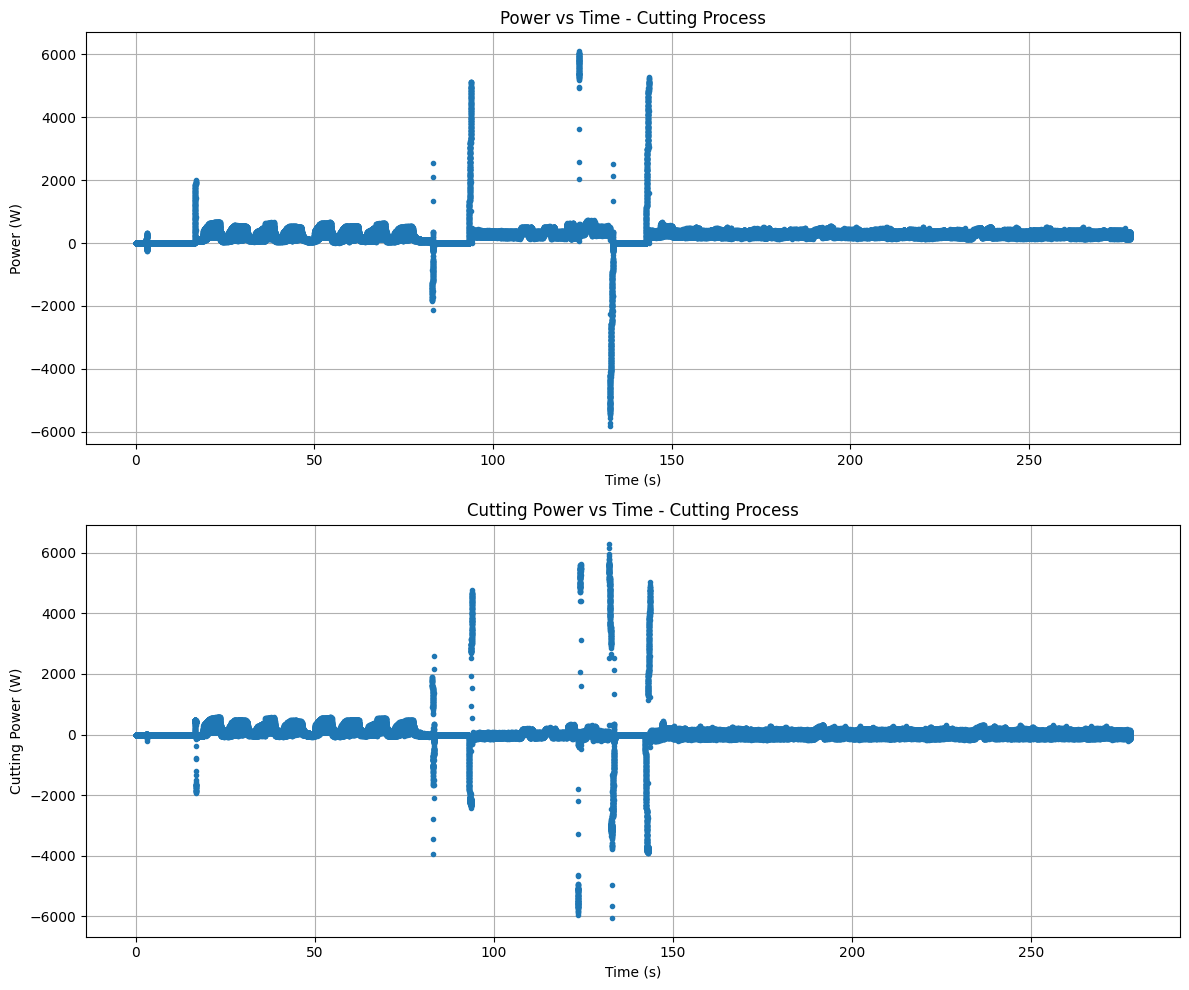

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(df5A1B['time'], df5A1B['power'], marker='.', linestyle='none')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Power (W)')
axes[0].set_title('Power vs Time - Cutting Process')
axes[0].grid(True)

axes[1].plot(df150['time'], df150['power'], marker='.', linestyle='none')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Cutting Power (W)')
axes[1].set_title('Cutting Power vs Time - Cutting Process')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Surface Milling

Surfacing interval (excluding power peaks) = $[18, 80]$ seconds.

Moreover, in the upper plot is shown a negative cutting power: it makes non sense to have a cutting component lower then zero (it means that cutting produces energy). Probably there is an inconsistency between the two sessions. So negative values are clipped to 0.

In [6]:
df150 = df150[(df150['time'] >= 18) & (df150['time'] <= 80)]

# $$$ valuta questa istruzione $$$
# NO physical sense a cutting power lower then 0 (incongruenza tra le sessioni...)
#df150['power'] = df150['power'].clip(lower=0)

# Revolution counter (just in the surfacing interval!)
Trev = 60/N # (s) revolution period
df150['rev'] = ((df150['time'] - df150['time'].iloc[0])/Trev).astype(int)
df150.insert(0, 'rev', df150.pop('rev'))

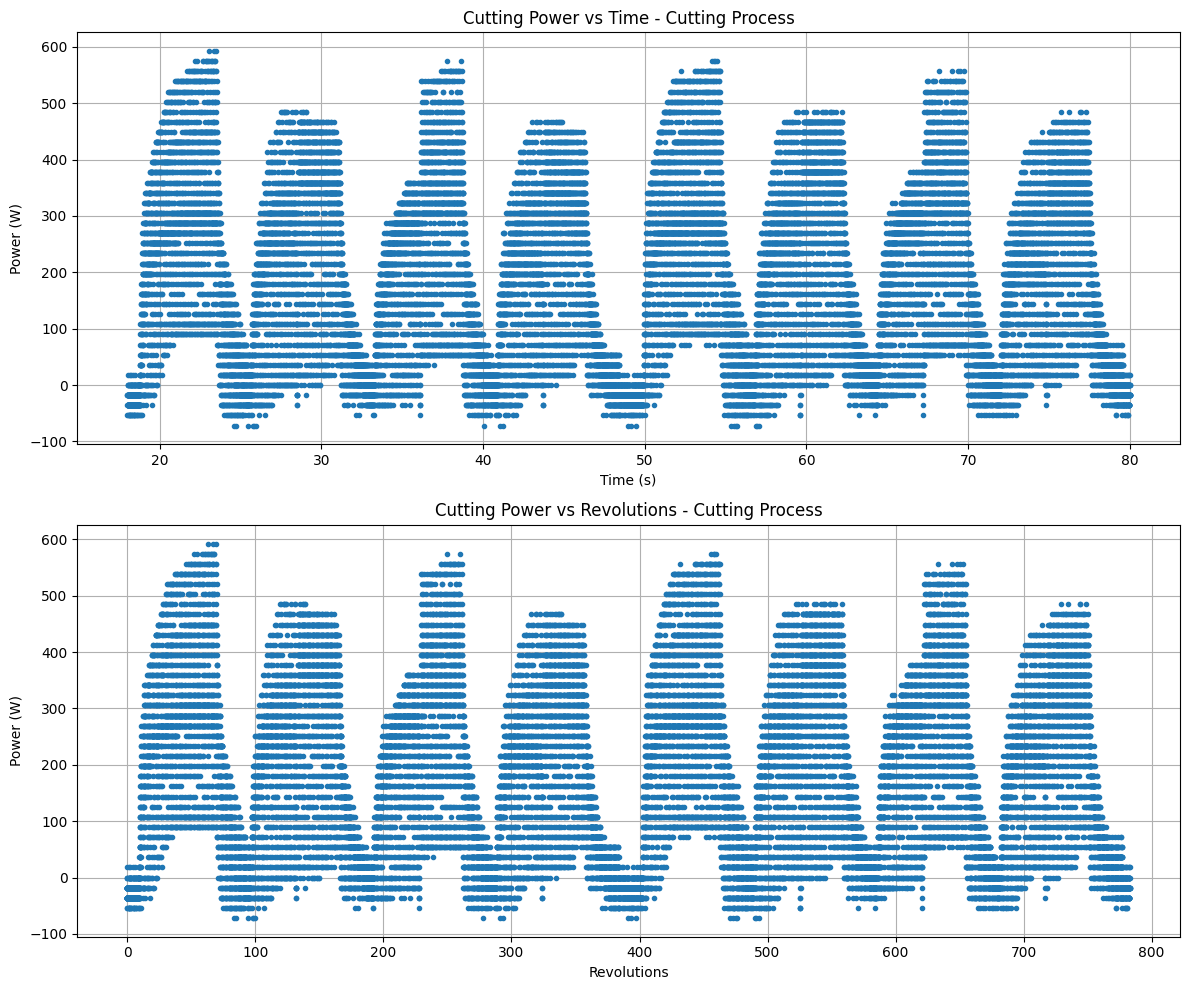

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(df150['time'], df150['power'], marker='.', linestyle='none')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Power (W)')
axes[0].set_title('Cutting Power vs Time - Cutting Process')
axes[0].grid(True)

axes[1].plot(df150['rev'], df150['power'], marker='.', linestyle='none')
axes[1].set_xlabel('Revolutions')
axes[1].set_ylabel('Power (W)')
axes[1].set_title('Cutting Power vs Revolutions - Cutting Process')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
stats = df150.groupby('rev')['power'].agg(
    mean_power='mean',
    min_power='min',
    max_power='max'
).reset_index()